In [1]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

print("torch:", torch.__version__)
print("GPU var mı:", torch.cuda.is_available())

torch: 2.15.0+cpu
GPU var mı: False


In [2]:
df = pd.read_csv("../data/energydata_complete.csv", parse_dates=["date"])
print(df.shape)
df.head()

(19735, 29)


,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,...,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2
0,2016-01-11 17:00:00,60,30,19.89,47.596667,19.2,44.790000,19.79,44.730000,19.000000,...,17.033333,45.53,6.600000,733.5,92.0,7.000000,63.000000,5.3,13.275433,13.275433
1,2016-01-11 17:10:00,60,30,19.89,46.693333,19.2,44.722500,19.79,44.790000,19.000000,...,17.066667,45.56,6.483333,733.6,92.0,6.666667,59.166667,5.2,18.606195,18.606195
2,2016-01-11 17:20:00,50,30,19.89,46.300000,19.2,44.626667,19.79,44.933333,18.926667,...,17.000000,45.50,6.366667,733.7,92.0,6.333333,55.333333,5.1,28.642668,28.642668
3,2016-01-11 17:30:00,50,40,19.89,46.066667,19.2,44.590000,19.79,45.000000,18.890000,...,17.000000,45.40,6.250000,733.8,92.0,6.000000,51.500000,5.0,45.410389,45.410389
4,2016-01-11 17:40:00,60,40,19.89,46.333333,19.2,44.530000,19.79,45.000000,18.890000,...,17.000000,45.40,6.133333,733.9,92.0,5.666667,47.666667,4.9,10.084097,10.084097


In [3]:
df.info()
print("Eksik değer:", df.isna().sum().sum())
df.describe().T

<class 'pandas.DataFrame'>
RangeIndex: 19735 entries, 0 to 19734
Data columns (total 29 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   date         19735 non-null  datetime64[us]
 1   Appliances   19735 non-null  int64         
 2   lights       19735 non-null  int64         
 3   T1           19735 non-null  float64       
 4   RH_1         19735 non-null  float64       
 5   T2           19735 non-null  float64       
 6   RH_2         19735 non-null  float64       
 7   T3           19735 non-null  float64       
 8   RH_3         19735 non-null  float64       
 9   T4           19735 non-null  float64       
 10  RH_4         19735 non-null  float64       
 11  T5           19735 non-null  float64       
 12  RH_5         19735 non-null  float64       
 13  T6           19735 non-null  float64       
 14  RH_6         19735 non-null  float64       
 15  T7           19735 non-null  float64       
 16  RH_7         19

,count,mean,min,25%,50%,75%,max,std
date,19735,2016-03-20 05:29:59.999999,2016-01-11 17:00:00,2016-02-14 23:15:00,2016-03-20 05:30:00,2016-04-23 11:45:00,2016-05-27 18:00:00,NaN
Appliances,19735.0,97.694958,10.0,50.0,60.0,100.0,1080.0,102.524891
lights,19735.0,3.801875,0.0,0.0,0.0,0.0,70.0,7.935988
T1,19735.0,21.686571,16.79,20.76,21.6,22.6,26.26,1.606066
RH_1,19735.0,40.259739,27.023333,37.333333,39.656667,43.066667,63.36,3.979299
T2,19735.0,20.341219,16.1,18.79,20.0,21.5,29.856667,2.192974
RH_2,19735.0,40.42042,20.463333,37.9,40.5,43.26,56.026667,4.069813
T3,19735.0,22.267611,17.2,20.79,22.1,23.29,29.236,2.006111
RH_3,19735.0,39.2425,28.766667,36.9,38.53,41.76,50.163333,3.254576
T4,19735.0,20.855335,15.1,19.53,20.666667,22.1,26.2,2.042884


In [4]:
import os
os.makedirs("../figures", exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 100,
    "savefig.dpi": 300,
    "font.size": 11,
    "axes.grid": True,
    "grid.alpha": 0.3,
})
print("Hazır")

Hazır


In [5]:
y = df["Appliances"]
print(y.describe())
print("Çarpıklık (skewness):", round(y.skew(), 3))
print("Basıklık (kurtosis):", round(y.kurt(), 3))
print("Medyan:", y.median(), "| Ortalama:", round(y.mean(), 2))

count    19735.000000
mean        97.694958
std        102.524891
min         10.000000
25%         50.000000
50%         60.000000
75%        100.000000
max       1080.000000
Name: Appliances, dtype: float64
Çarpıklık (skewness): 3.386
Basıklık (kurtosis): 13.668
Medyan: 60.0 | Ortalama: 97.69


C:\Users\alper\AppData\Local\Temp\ipykernel_24128\621139635.py:8: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1].boxplot(y, vert=True, patch_artist=True,


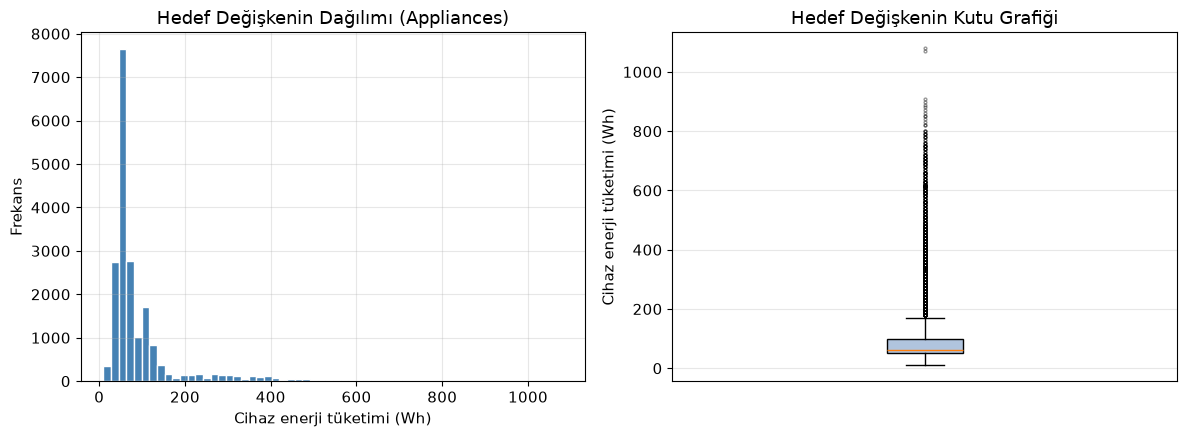

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].hist(y, bins=60, color="steelblue", edgecolor="white")
axes[0].set_title("Hedef Değişkenin Dağılımı (Appliances)")
axes[0].set_xlabel("Cihaz enerji tüketimi (Wh)")
axes[0].set_ylabel("Frekans")

axes[1].boxplot(y, vert=True, patch_artist=True,
                boxprops=dict(facecolor="lightsteelblue"),
                flierprops=dict(marker="o", markersize=2, alpha=0.4))
axes[1].set_title("Hedef Değişkenin Kutu Grafiği")
axes[1].set_ylabel("Cihaz enerji tüketimi (Wh)")
axes[1].set_xticks([])

plt.tight_layout()
plt.savefig("../figures/G1_hedef_dagilimi.png", dpi=300, bbox_inches="tight")
plt.show()

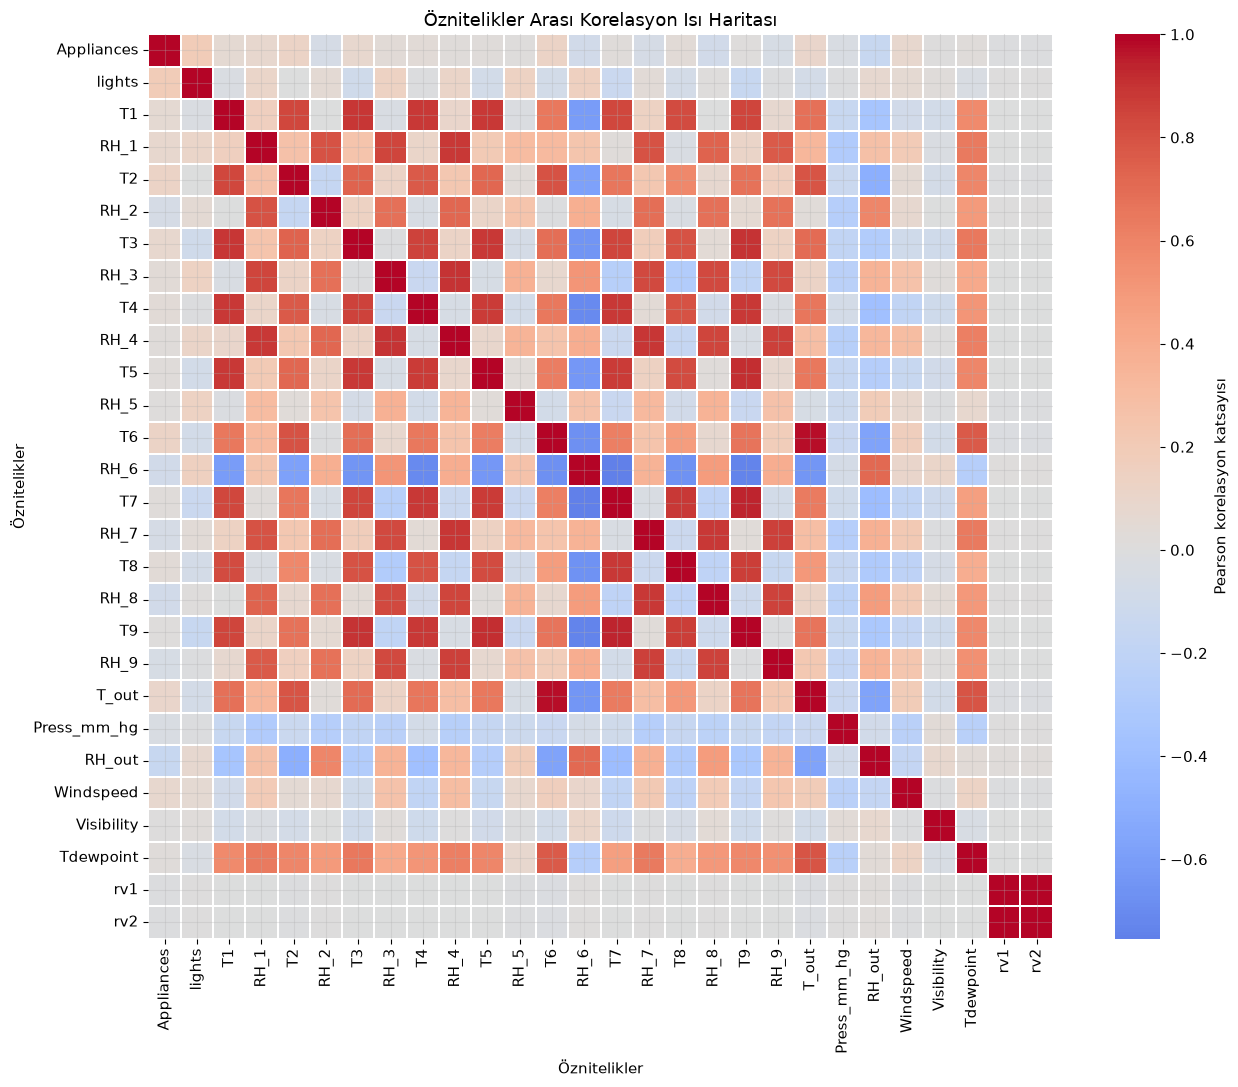

Appliances     1.000
lights         0.197
T2             0.120
T6             0.118
T_out          0.099
Windspeed      0.087
RH_1           0.086
T3             0.085
T1             0.055
T4             0.040
T8             0.040
RH_3           0.036
T7             0.026
T5             0.020
RH_4           0.017
Tdewpoint      0.015
T9             0.010
RH_5           0.007
Visibility     0.000
rv1           -0.011
rv2           -0.011
Press_mm_hg   -0.035
RH_9          -0.051
RH_7          -0.056
RH_2          -0.060
RH_6          -0.083
RH_8          -0.094
RH_out        -0.152
Name: Appliances, dtype: float64


In [7]:
corr = df.drop(columns=["date"]).corr()

plt.figure(figsize=(14, 11))
sns.heatmap(corr, cmap="coolwarm", center=0, square=True,
            linewidths=0.3, cbar_kws={"label": "Pearson korelasyon katsayısı"})
plt.title("Öznitelikler Arası Korelasyon Isı Haritası")
plt.xlabel("Öznitelikler")
plt.ylabel("Öznitelikler")
plt.tight_layout()
plt.savefig("../figures/G2_korelasyon.png", dpi=300, bbox_inches="tight")
plt.show()

print(corr["Appliances"].sort_values(ascending=False).round(3))

In [8]:
from sklearn.preprocessing import StandardScaler

# Zaman özniteliklerini ekle
df["hour"] = df["date"].dt.hour
df["dayofweek"] = df["date"].dt.dayofweek

# rv1 ve rv2 rastgele değişken, çıkarıyoruz
feature_cols = [c for c in df.columns if c not in ["date", "Appliances", "rv1", "rv2"]]
target_col = "Appliances"

n = len(df)
i_train = int(n * 0.70)
i_val = int(n * 0.85)

train = df.iloc[:i_train]
val = df.iloc[i_train:i_val]
test = df.iloc[i_val:]

print("Eğitim:", train.shape, train["date"].min(), "->", train["date"].max())
print("Doğrulama:", val.shape, val["date"].min(), "->", val["date"].max())
print("Test:", test.shape, test["date"].min(), "->", test["date"].max())

# Scaler yalnızca eğitim setine fit edilir
scaler = StandardScaler().fit(train[feature_cols])
X_train = scaler.transform(train[feature_cols])
X_val = scaler.transform(val[feature_cols])
X_test = scaler.transform(test[feature_cols])

y_train = train[target_col].values
y_val = val[target_col].values
y_test = test[target_col].values

print("Öznitelik sayısı:", len(feature_cols))

Eğitim: (13814, 31) 2016-01-11 17:00:00 -> 2016-04-16 15:10:00
Doğrulama: (2960, 31) 2016-04-16 15:20:00 -> 2016-05-07 04:30:00
Test: (2961, 31) 2016-05-07 04:40:00 -> 2016-05-27 18:00:00
Öznitelik sayısı: 27


C:\Users\alper\AppData\Local\Temp\ipykernel_24128\3088325662.py:5: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["dayofweek"] = df["date"].dt.dayofweek


In [9]:
import os
os.makedirs("../figures", exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 100,
    "savefig.dpi": 300,
    "font.size": 11,
    "axes.grid": True,
    "grid.alpha": 0.3,
})
print("Hazır")

Hazır


In [10]:
y = df["Appliances"]
print(y.describe())
print("Çarpıklık (skewness):", round(y.skew(), 3))
print("Basıklık (kurtosis):", round(y.kurt(), 3))
print("Medyan:", y.median(), "| Ortalama:", round(y.mean(), 2))

count    19735.000000
mean        97.694958
std        102.524891
min         10.000000
25%         50.000000
50%         60.000000
75%        100.000000
max       1080.000000
Name: Appliances, dtype: float64
Çarpıklık (skewness): 3.386
Basıklık (kurtosis): 13.668
Medyan: 60.0 | Ortalama: 97.69


C:\Users\alper\AppData\Local\Temp\ipykernel_24128\621139635.py:8: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1].boxplot(y, vert=True, patch_artist=True,


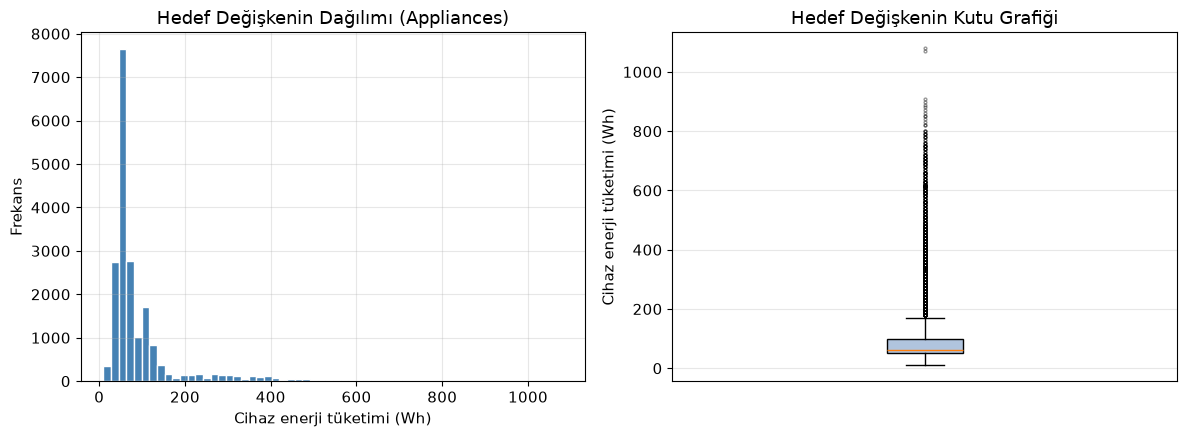

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].hist(y, bins=60, color="steelblue", edgecolor="white")
axes[0].set_title("Hedef Değişkenin Dağılımı (Appliances)")
axes[0].set_xlabel("Cihaz enerji tüketimi (Wh)")
axes[0].set_ylabel("Frekans")

axes[1].boxplot(y, vert=True, patch_artist=True,
                boxprops=dict(facecolor="lightsteelblue"),
                flierprops=dict(marker="o", markersize=2, alpha=0.4))
axes[1].set_title("Hedef Değişkenin Kutu Grafiği")
axes[1].set_ylabel("Cihaz enerji tüketimi (Wh)")
axes[1].set_xticks([])

plt.tight_layout()
plt.savefig("../figures/G1_hedef_dagilimi.png", dpi=300, bbox_inches="tight")
plt.show()

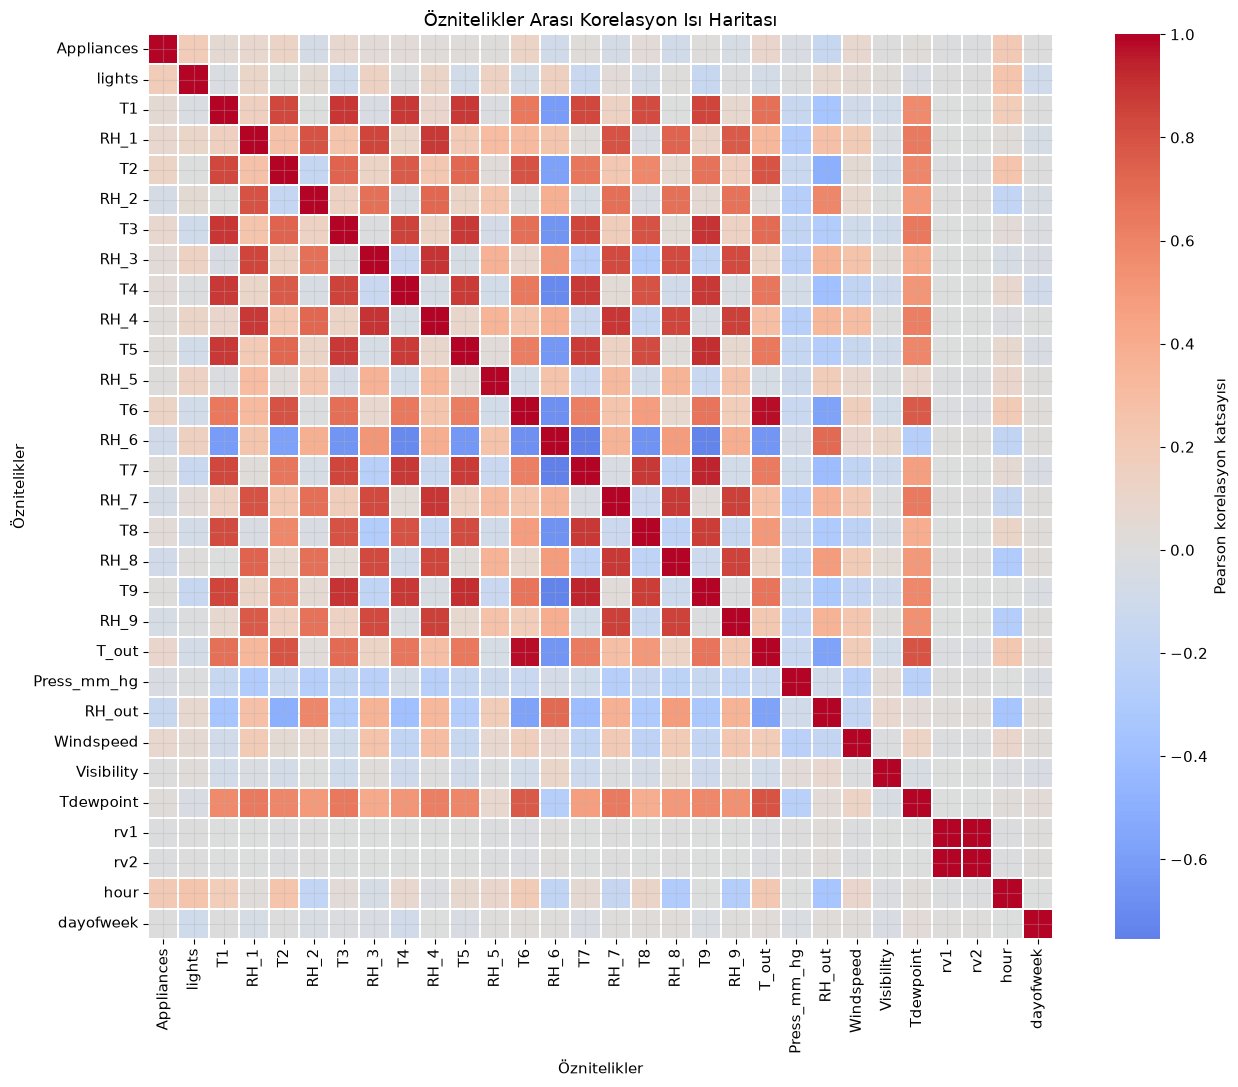

Appliances     1.000
hour           0.217
lights         0.197
T2             0.120
T6             0.118
T_out          0.099
Windspeed      0.087
RH_1           0.086
T3             0.085
T1             0.055
T4             0.040
T8             0.040
RH_3           0.036
T7             0.026
T5             0.020
RH_4           0.017
Tdewpoint      0.015
T9             0.010
RH_5           0.007
dayofweek      0.003
Visibility     0.000
rv2           -0.011
rv1           -0.011
Press_mm_hg   -0.035
RH_9          -0.051
RH_7          -0.056
RH_2          -0.060
RH_6          -0.083
RH_8          -0.094
RH_out        -0.152
Name: Appliances, dtype: float64


In [12]:
corr = df.drop(columns=["date"]).corr()

plt.figure(figsize=(14, 11))
sns.heatmap(corr, cmap="coolwarm", center=0, square=True,
            linewidths=0.3, cbar_kws={"label": "Pearson korelasyon katsayısı"})
plt.title("Öznitelikler Arası Korelasyon Isı Haritası")
plt.xlabel("Öznitelikler")
plt.ylabel("Öznitelikler")
plt.tight_layout()
plt.savefig("../figures/G2_korelasyon.png", dpi=300, bbox_inches="tight")
plt.show()

print(corr["Appliances"].sort_values(ascending=False).round(3))

In [13]:
from sklearn.preprocessing import StandardScaler

# Zaman özniteliklerini ekle
df["hour"] = df["date"].dt.hour
df["dayofweek"] = df["date"].dt.dayofweek

# rv1 ve rv2 rastgele değişken, çıkarıyoruz
feature_cols = [c for c in df.columns if c not in ["date", "Appliances", "rv1", "rv2"]]
target_col = "Appliances"

n = len(df)
i_train = int(n * 0.70)
i_val = int(n * 0.85)

train = df.iloc[:i_train]
val = df.iloc[i_train:i_val]
test = df.iloc[i_val:]

print("Eğitim:", train.shape, train["date"].min(), "->", train["date"].max())
print("Doğrulama:", val.shape, val["date"].min(), "->", val["date"].max())
print("Test:", test.shape, test["date"].min(), "->", test["date"].max())

# Scaler yalnızca eğitim setine fit edilir
scaler = StandardScaler().fit(train[feature_cols])
X_train = scaler.transform(train[feature_cols])
X_val = scaler.transform(val[feature_cols])
X_test = scaler.transform(test[feature_cols])

y_train = train[target_col].values
y_val = val[target_col].values
y_test = test[target_col].values

print("Öznitelik sayısı:", len(feature_cols))

Eğitim: (13814, 31) 2016-01-11 17:00:00 -> 2016-04-16 15:10:00
Doğrulama: (2960, 31) 2016-04-16 15:20:00 -> 2016-05-07 04:30:00
Test: (2961, 31) 2016-05-07 04:40:00 -> 2016-05-27 18:00:00
Öznitelik sayısı: 27


C:\Users\alper\AppData\Local\Temp\ipykernel_24128\3088325662.py:5: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["dayofweek"] = df["date"].dt.dayofweek


In [14]:
from sklearn.preprocessing import StandardScaler

# Zaman özniteliklerini ekle
df["hour"] = df["date"].dt.hour
df["dayofweek"] = df["date"].dt.day_of_week

# rv1 ve rv2 rastgele değişken, çıkarıyoruz
feature_cols = [c for c in df.columns if c not in ["date", "Appliances", "rv1", "rv2"]]
target_col = "Appliances"

n = len(df)
i_train = int(n * 0.70)
i_val = int(n * 0.85)

train = df.iloc[:i_train]
val = df.iloc[i_train:i_val]
test = df.iloc[i_val:]

print("Eğitim:", train.shape, train["date"].min(), "->", train["date"].max())
print("Doğrulama:", val.shape, val["date"].min(), "->", val["date"].max())
print("Test:", test.shape, test["date"].min(), "->", test["date"].max())

# Scaler yalnızca eğitim setine fit edilir
scaler = StandardScaler().fit(train[feature_cols])
X_train = scaler.transform(train[feature_cols])
X_val = scaler.transform(val[feature_cols])
X_test = scaler.transform(test[feature_cols])

y_train = train[target_col].values
y_val = val[target_col].values
y_test = test[target_col].values

print("Öznitelik sayısı:", len(feature_cols))

Eğitim: (13814, 31) 2016-01-11 17:00:00 -> 2016-04-16 15:10:00
Doğrulama: (2960, 31) 2016-04-16 15:20:00 -> 2016-05-07 04:30:00
Test: (2961, 31) 2016-05-07 04:40:00 -> 2016-05-27 18:00:00
Öznitelik sayısı: 27


In [15]:
for name, part in [("Eğitim", train), ("Doğrulama", val), ("Test", test)]:
    s = part["Appliances"]
    print(f"{name}: ort={s.mean():.1f} | medyan={s.median():.1f} | std={s.std():.1f} | maks={s.max():.0f}")

Eğitim: ort=98.8 | medyan=60.0 | std=106.9 | maks=1080
Doğrulama: ort=93.4 | medyan=60.0 | std=92.3 | maks=870
Test: ort=96.9 | medyan=60.0 | std=90.9 | maks=850


In [16]:
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Hedef yalnızca eğitim istatistikleriyle standartlaştırılır
y_mu, y_sd = y_train.mean(), y_train.std()

def to_t(a):
    return torch.tensor(a, dtype=torch.float32)

Xtr, Xva, Xte = to_t(X_train), to_t(X_val), to_t(X_test)
ytr_s = to_t((y_train - y_mu) / y_sd).unsqueeze(1)
yva_s = to_t((y_val - y_mu) / y_sd).unsqueeze(1)

print("Cihaz:", device, "| Eğitim tensörü:", Xtr.shape)

Cihaz: cpu | Eğitim tensörü: torch.Size([13814, 27])


In [17]:
class MLP(nn.Module):
    def __init__(self, in_dim, hidden=(128, 64, 32)):
        super().__init__()
        layers, d = [], in_dim
        for h in hidden:
            layers += [nn.Linear(d, h), nn.ReLU()]
            d = h
        layers.append(nn.Linear(d, 1))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


def predict_wh(model, X):
    """Tahminleri orijinal birime (Wh) geri çevirir."""
    model.eval()
    with torch.no_grad():
        p = model(X.to(device)).cpu().numpy().ravel()
    return p * y_sd + y_mu


def metrics(y_true, y_pred):
    err = y_pred - y_true
    rmse = np.sqrt(np.mean(err ** 2))
    mae = np.mean(np.abs(err))
    r2 = 1 - np.sum(err ** 2) / np.sum((y_true - y_true.mean()) ** 2)
    return {"RMSE": rmse, "MAE": mae, "R2": r2}


def train_model(loss_fn, seed, epochs=100, lr=1e-3, batch_size=128, patience=10):
    set_seed(seed)
    model = MLP(Xtr.shape[1]).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    g = torch.Generator().manual_seed(seed)
    loader = DataLoader(TensorDataset(Xtr, ytr_s), batch_size=batch_size,
                        shuffle=True, generator=g)

    hist = {"train_loss": [], "val_loss": [], "val_rmse": []}
    best, best_state, wait = float("inf"), None, 0

    for ep in range(epochs):
        model.train()
        total = 0.0
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            opt.step()
            total += loss.item() * len(xb)

        model.eval()
        with torch.no_grad():
            val_loss = loss_fn(model(Xva.to(device)), yva_s.to(device)).item()
        val_rmse = metrics(y_val, predict_wh(model, Xva))["RMSE"]

        hist["train_loss"].append(total / len(Xtr))
        hist["val_loss"].append(val_loss)
        hist["val_rmse"].append(val_rmse)

        if val_loss < best:
            best = val_loss
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                break

    model.load_state_dict(best_state)
    return model, hist

In [18]:
model, hist = train_model(nn.MSELoss(), seed=42)

print("Durduğu epoch:", len(hist["train_loss"]))
print("Test sonuçları:", {k: round(float(v), 3) for k, v in metrics(y_test, predict_wh(model, Xte)).items()})
print("Val sonuçları :", {k: round(float(v), 3) for k, v in metrics(y_val, predict_wh(model, Xva)).items()})

Durduğu epoch: 12
Test sonuçları: {'RMSE': 85.95, 'MAE': 50.986, 'R2': 0.105}
Val sonuçları : {'RMSE': 86.948, 'MAE': 49.16, 'R2': 0.111}


In [19]:
from sklearn.linear_model import Ridge

base = {}
base["Eğitim ortalaması"] = metrics(y_test, np.full_like(y_test, y_train.mean(), dtype=float))
base["Eğitim medyanı"] = metrics(y_test, np.full_like(y_test, np.median(y_train), dtype=float))
lin = Ridge(alpha=1.0).fit(X_train, y_train)
base["Ridge regresyon"] = metrics(y_test, lin.predict(X_test))

for k, v in base.items():
    print(f"{k:20s}", {m: round(float(x), 3) for m, x in v.items()})

Eğitim ortalaması    {'RMSE': 90.892, 'MAE': 52.829, 'R2': -0.0}
Eğitim medyanı       {'RMSE': 98.089, 'MAE': 43.256, 'R2': -0.165}
Ridge regresyon      {'RMSE': 88.297, 'MAE': 59.004, 'R2': 0.056}


In [20]:
def log_cosh_loss(pred, target):
    x = pred - target
    return torch.mean(x + torch.nn.functional.softplus(-2.0 * x) - np.log(2.0))

LOSSES = {
    "MSE": nn.MSELoss(),
    "MAE": nn.L1Loss(),
    "Huber": nn.HuberLoss(delta=1.0),   # delta standartlaştırılmış birimde
    "Log-cosh": log_cosh_loss,
}

def train_model(loss_fn, seed, epochs=100, lr=1e-3, batch_size=128, patience=10):
    set_seed(seed)
    model = MLP(Xtr.shape[1]).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    g = torch.Generator().manual_seed(seed)
    loader = DataLoader(TensorDataset(Xtr, ytr_s), batch_size=batch_size,
                        shuffle=True, generator=g)

    hist = {"train_loss": [], "val_loss": [], "val_rmse": []}
    best, best_state, wait = float("inf"), None, 0

    for ep in range(epochs):
        model.train()
        total = 0.0
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            opt.step()
            total += loss.item() * len(xb)

        model.eval()
        with torch.no_grad():
            val_loss = loss_fn(model(Xva.to(device)), yva_s.to(device)).item()
        val_rmse = metrics(y_val, predict_wh(model, Xva))["RMSE"]

        hist["train_loss"].append(total / len(Xtr))
        hist["val_loss"].append(val_loss)
        hist["val_rmse"].append(val_rmse)

        if val_rmse < best:          # ortak ölçüt: doğrulama RMSE
            best = val_rmse
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                break

    model.load_state_dict(best_state)
    return model, hist
print("Hazır")

Hazır


In [21]:
import time
SEEDS = [42, 43, 44, 45, 46]
results, histories, preds_seed42 = [], {}, {}

t0 = time.time()
for lname, lfn in LOSSES.items():
    for s in SEEDS:
        model, hist = train_model(lfn, seed=s)
        p = predict_wh(model, Xte)
        m = metrics(y_test, p)
        results.append({"Kayıp": lname, "Seed": s, "Epoch": len(hist["train_loss"]), **m})
        histories[(lname, s)] = hist
        if s == 42:
            preds_seed42[lname] = p
        print(f"{lname:9s} seed={s} epoch={len(hist['train_loss']):3d} "
              f"RMSE={m['RMSE']:.2f} MAE={m['MAE']:.2f} R2={m['R2']:.3f}")
print(f"Toplam süre: {(time.time()-t0)/60:.1f} dk")

MSE       seed=42 epoch= 12 RMSE=85.95 MAE=50.99 R2=0.105
MSE       seed=43 epoch= 14 RMSE=89.13 MAE=52.64 R2=0.038
MSE       seed=44 epoch= 14 RMSE=99.39 MAE=67.15 R2=-0.196
MSE       seed=45 epoch= 11 RMSE=87.94 MAE=53.10 R2=0.064
MSE       seed=46 epoch= 11 RMSE=96.92 MAE=69.89 R2=-0.137
MAE       seed=42 epoch= 13 RMSE=85.14 MAE=41.08 R2=0.122
MAE       seed=43 epoch= 14 RMSE=86.64 MAE=42.20 R2=0.091
MAE       seed=44 epoch= 13 RMSE=84.70 MAE=43.89 R2=0.131
MAE       seed=45 epoch= 13 RMSE=85.22 MAE=41.36 R2=0.121
MAE       seed=46 epoch= 13 RMSE=85.70 MAE=43.55 R2=0.111
Huber     seed=42 epoch= 12 RMSE=85.85 MAE=47.66 R2=0.107
Huber     seed=43 epoch= 14 RMSE=85.36 MAE=42.48 R2=0.118
Huber     seed=44 epoch= 13 RMSE=90.59 MAE=56.19 R2=0.006
Huber     seed=45 epoch= 13 RMSE=88.87 MAE=56.55 R2=0.044
Huber     seed=46 epoch= 13 RMSE=90.79 MAE=54.63 R2=0.002
Log-cosh  seed=42 epoch= 12 RMSE=85.88 MAE=49.34 R2=0.107
Log-cosh  seed=43 epoch= 14 RMSE=84.83 MAE=41.75 R2=0.129
Log-cosh  se

In [22]:
res = pd.DataFrame(results)
res.to_csv("../figures/T6_ham_sonuclar.csv", index=False)

summary = res.groupby("Kayıp")[["RMSE", "MAE", "R2"]].agg(["mean", "std"]).round(3)
summary = summary.loc[list(LOSSES.keys())]
print(summary)

            RMSE            MAE            R2       
            mean    std    mean    std   mean    std
Kayıp                                               
MSE       91.864  5.917  58.752  9.005 -0.025  0.133
MAE       85.483  0.739  42.416  1.267  0.115  0.015
Huber     88.294  2.570  51.504  6.194  0.055  0.055
Log-cosh  88.983  3.491  52.886  7.956  0.040  0.075


In [23]:
print(res.pivot(index="Seed", columns="Kayıp", values="RMSE").round(2))
print()
print(res.pivot(index="Seed", columns="Kayıp", values="Epoch"))

Kayıp  Huber  Log-cosh    MAE    MSE
Seed                                
42     85.85     85.88  85.14  85.95
43     85.36     84.83  86.64  89.13
44     90.59     89.70  84.70  99.39
45     88.87     92.41  85.22  87.94
46     90.79     92.09  85.70  96.92

Kayıp  Huber  Log-cosh  MAE  MSE
Seed                            
42        12        12   13   12
43        14        14   14   14
44        13        13   13   14
45        13        13   13   11
46        13        13   13   11


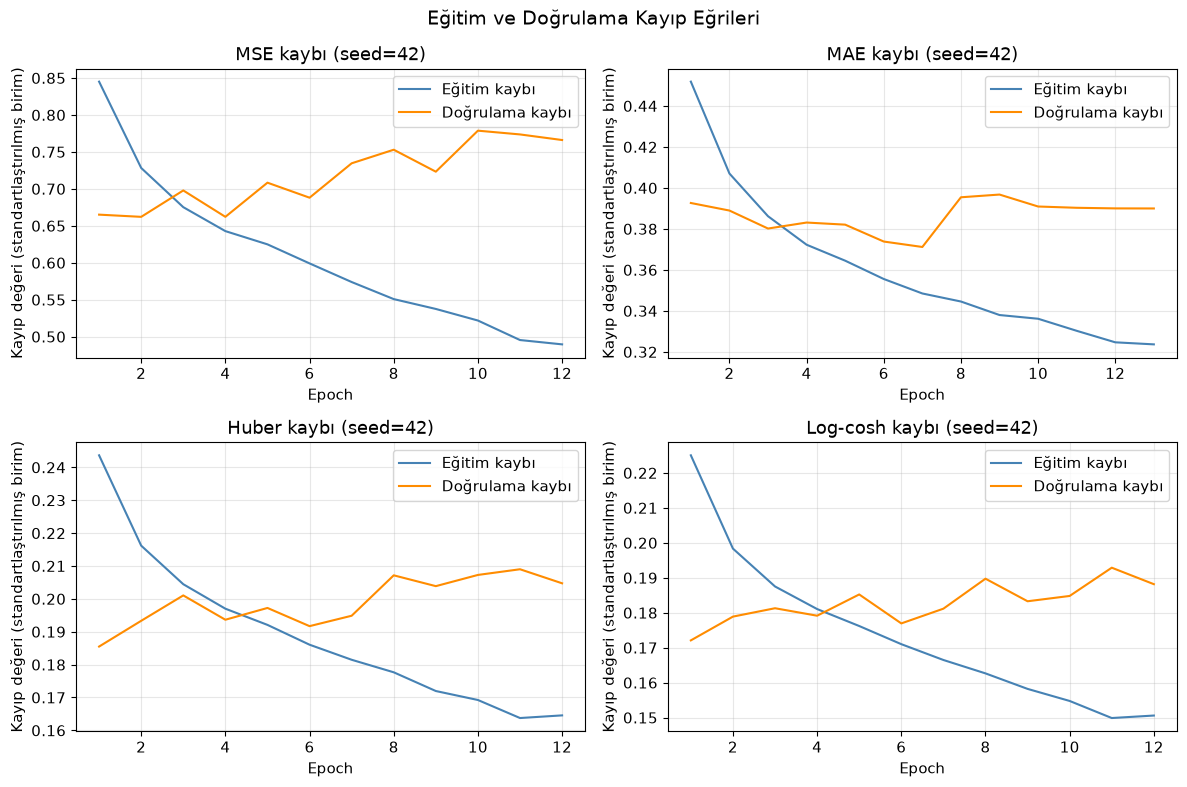

In [24]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, lname in zip(axes.ravel(), LOSSES.keys()):
    h = histories[(lname, 42)]
    ep = np.arange(1, len(h["train_loss"]) + 1)
    ax.plot(ep, h["train_loss"], label="Eğitim kaybı", color="steelblue")
    ax.plot(ep, h["val_loss"], label="Doğrulama kaybı", color="darkorange")
    ax.set_title(f"{lname} kaybı (seed=42)")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Kayıp değeri (standartlaştırılmış birim)")
    ax.legend()
plt.suptitle("Eğitim ve Doğrulama Kayıp Eğrileri", fontsize=14)
plt.tight_layout()
plt.savefig("../figures/G4_kayip_egrileri.png", dpi=300, bbox_inches="tight")
plt.show()

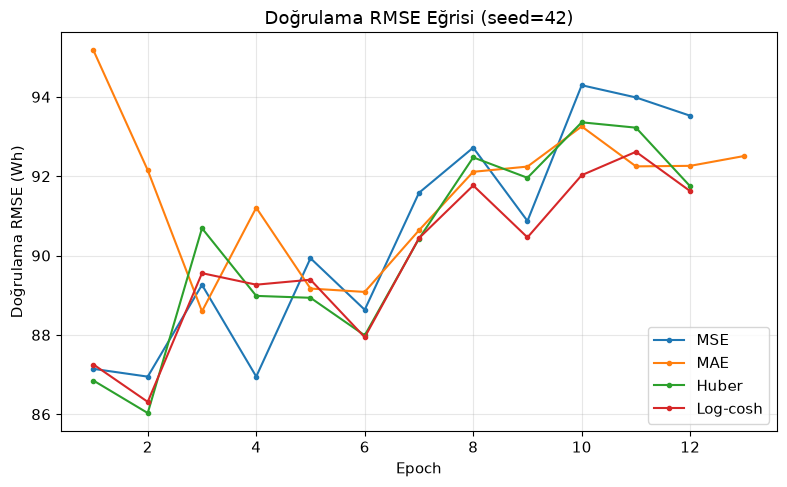

In [25]:
plt.figure(figsize=(8, 5))
for lname in LOSSES:
    h = histories[(lname, 42)]
    plt.plot(np.arange(1, len(h["val_rmse"]) + 1), h["val_rmse"], marker="o", markersize=3, label=lname)
plt.title("Doğrulama RMSE Eğrisi (seed=42)")
plt.xlabel("Epoch")
plt.ylabel("Doğrulama RMSE (Wh)")
plt.legend()
plt.tight_layout()
plt.savefig("../figures/G5_dogrulama_rmse.png", dpi=300, bbox_inches="tight")
plt.show()

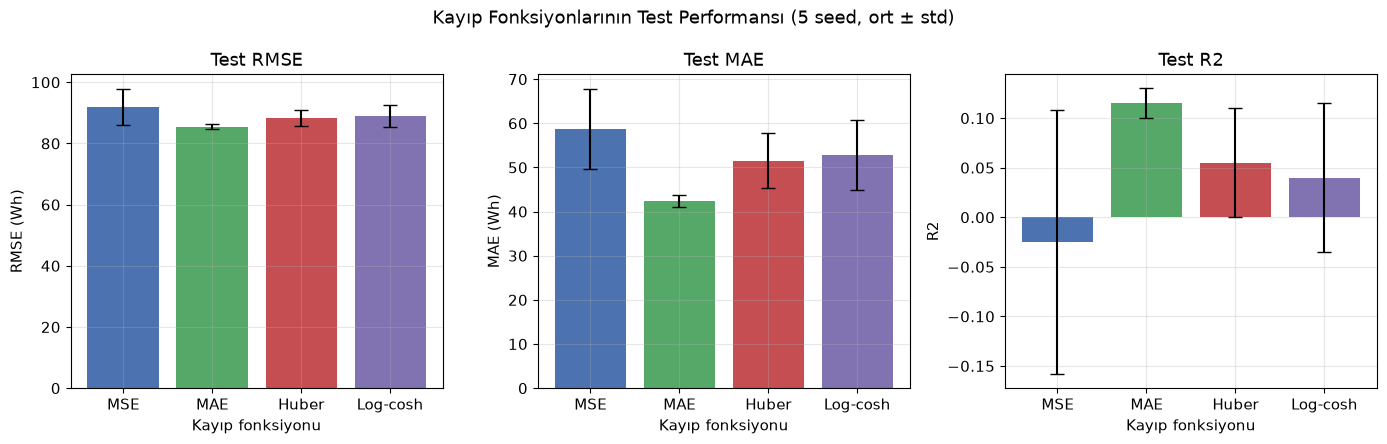

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
names = list(LOSSES.keys())
for ax, metric, unit in zip(axes, ["RMSE", "MAE", "R2"], ["Wh", "Wh", ""]):
    means = [summary[(metric, "mean")][n] for n in names]
    stds = [summary[(metric, "std")][n] for n in names]
    ax.bar(names, means, yerr=stds, capsize=5,
           color=["#4c72b0", "#55a868", "#c44e52", "#8172b2"])
    ax.set_title(f"Test {metric}")
    ax.set_xlabel("Kayıp fonksiyonu")
    ax.set_ylabel(f"{metric} ({unit})" if unit else metric)
plt.suptitle("Kayıp Fonksiyonlarının Test Performansı (5 seed, ort ± std)", fontsize=13)
plt.tight_layout()
plt.savefig("../figures/G6_karsilastirma.png", dpi=300, bbox_inches="tight")
plt.show()

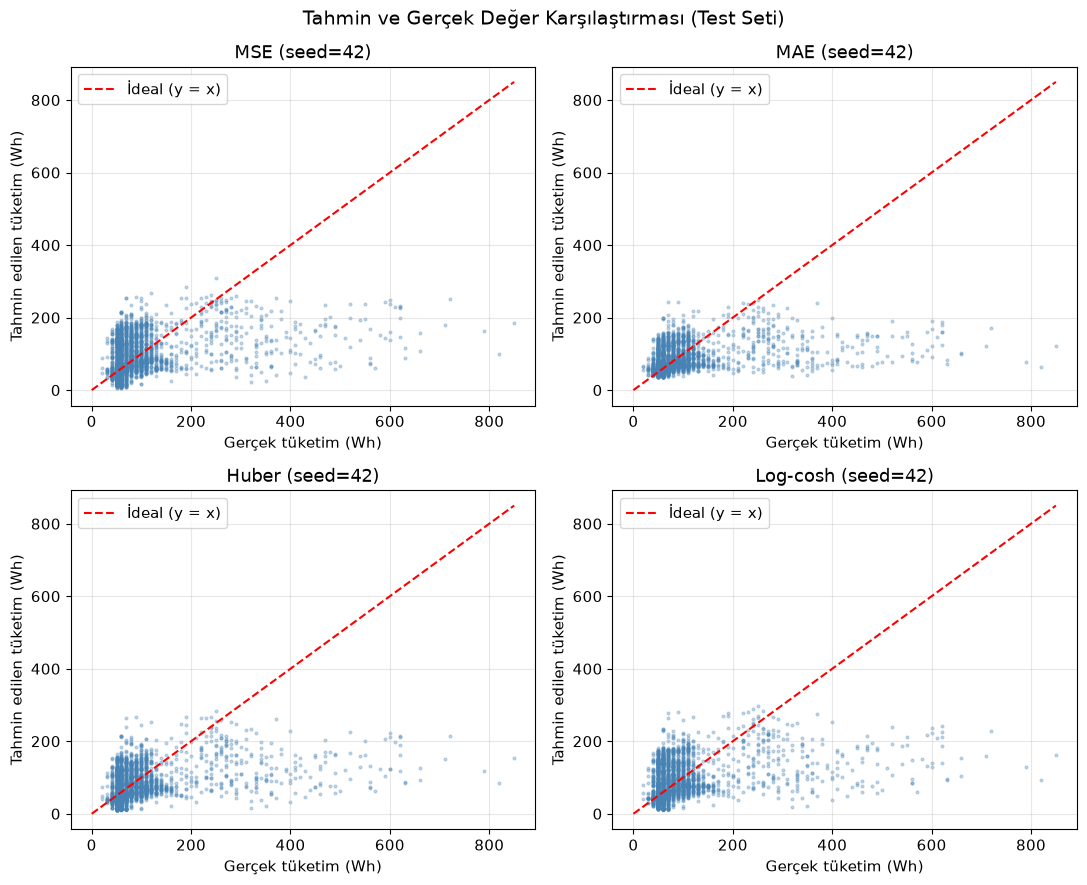

In [27]:
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for ax, lname in zip(axes.ravel(), LOSSES.keys()):
    p = preds_seed42[lname]
    ax.scatter(y_test, p, s=4, alpha=0.3, color="steelblue")
    lim = max(y_test.max(), p.max())
    ax.plot([0, lim], [0, lim], "r--", label="İdeal (y = x)")
    ax.set_title(f"{lname} (seed=42)")
    ax.set_xlabel("Gerçek tüketim (Wh)")
    ax.set_ylabel("Tahmin edilen tüketim (Wh)")
    ax.legend()
plt.suptitle("Tahmin ve Gerçek Değer Karşılaştırması (Test Seti)", fontsize=14)
plt.tight_layout()
plt.savefig("../figures/G7_tahmin_gercek.png", dpi=300, bbox_inches="tight")
plt.show()

In [28]:
def run_config(loss_fn, seeds=SEEDS, hidden=(128, 64, 32), lr=1e-3,
               weight_decay=0.0, dropout=0.0):
    out = []
    for s in seeds:
        set_seed(s)
        layers, d = [], Xtr.shape[1]
        for h in hidden:
            layers += [nn.Linear(d, h), nn.ReLU()]
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            d = h
        layers.append(nn.Linear(d, 1))
        model = nn.Sequential(*layers).to(device)
        opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
        g = torch.Generator().manual_seed(s)
        loader = DataLoader(TensorDataset(Xtr, ytr_s), batch_size=128, shuffle=True, generator=g)
        best, best_state, wait = float("inf"), None, 0
        for ep in range(100):
            model.train()
            for xb, yb in loader:
                xb, yb = xb.to(device), yb.to(device)
                opt.zero_grad()
                loss_fn(model(xb), yb).backward()
                opt.step()
            model.eval()
            with torch.no_grad():
                p = model(Xva.to(device)).cpu().numpy().ravel() * y_sd + y_mu
            v = metrics(y_val, p)["RMSE"]
            if v < best:
                best = v
                best_state = {k: t.clone() for k, t in model.state_dict().items()}
                wait = 0
            else:
                wait += 1
                if wait >= 10:
                    break
        model.load_state_dict(best_state)
        model.eval()
        with torch.no_grad():
            pt = model(Xte.to(device)).cpu().numpy().ravel() * y_sd + y_mu
        out.append(metrics(y_test, pt))
    df_ = pd.DataFrame(out)
    return {f"{m}": f"{df_[m].mean():.2f} ± {df_[m].std():.2f}" for m in ["RMSE", "MAE", "R2"]}
print("Hazır")

Hazır


In [29]:
abl = []
def add(name, lname, **kw):
    r = run_config(LOSSES[lname] if lname in LOSSES else lname, **kw)
    abl.append({"Konfigürasyon": name, "Kayıp": lname, **r})
    print(abl[-1])

# 1) Huber delta duyarlılığı
for d in [0.1, 0.5, 1.0, 2.0]:
    add(f"Huber δ={d}", "Huber", ) if d == 1.0 else None
    if d != 1.0:
        r = run_config(nn.HuberLoss(delta=d))
        abl.append({"Konfigürasyon": f"Huber δ={d}", "Kayıp": "Huber", **r}); print(abl[-1])

# 2) Ağ derinliği / genişliği (MAE ve MSE)
for lname in ["MAE", "MSE"]:
    for hid in [(32,), (64, 32), (128, 64, 32), (256, 128, 64, 32)]:
        add(f"{lname}, katmanlar={hid}", lname, hidden=hid)

# 3) Ağırlık sönümü (L2) ve dropout
for lname in ["MAE", "MSE"]:
    add(f"{lname}, weight_decay=1e-3", lname, weight_decay=1e-3)
    add(f"{lname}, dropout=0.3", lname, dropout=0.3)

pd.DataFrame(abl).to_csv("../figures/T7_ablasyon.csv", index=False)
print("Bitti")

{'Konfigürasyon': 'Huber δ=0.1', 'Kayıp': 'Huber', 'RMSE': '85.62 ± 0.97', 'MAE': '44.17 ± 2.94', 'R2': '0.11 ± 0.02'}
{'Konfigürasyon': 'Huber δ=0.5', 'Kayıp': 'Huber', 'RMSE': '88.69 ± 6.38', 'MAE': '50.00 ± 6.71', 'R2': '0.04 ± 0.14'}
{'Konfigürasyon': 'Huber δ=1.0', 'Kayıp': 'Huber', 'RMSE': '88.29 ± 2.57', 'MAE': '51.50 ± 6.19', 'R2': '0.06 ± 0.05'}
{'Konfigürasyon': 'Huber δ=2.0', 'Kayıp': 'Huber', 'RMSE': '93.22 ± 7.57', 'MAE': '60.49 ± 11.06', 'R2': '-0.06 ± 0.17'}
{'Konfigürasyon': 'MAE, katmanlar=(32,)', 'Kayıp': 'MAE', 'RMSE': '86.50 ± 1.66', 'MAE': '43.15 ± 0.96', 'R2': '0.09 ± 0.03'}
{'Konfigürasyon': 'MAE, katmanlar=(64, 32)', 'Kayıp': 'MAE', 'RMSE': '87.73 ± 3.77', 'MAE': '50.36 ± 9.64', 'R2': '0.07 ± 0.08'}
{'Konfigürasyon': 'MAE, katmanlar=(128, 64, 32)', 'Kayıp': 'MAE', 'RMSE': '85.48 ± 0.74', 'MAE': '42.42 ± 1.27', 'R2': '0.12 ± 0.02'}
{'Konfigürasyon': 'MAE, katmanlar=(256, 128, 64, 32)', 'Kayıp': 'MAE', 'RMSE': '91.34 ± 8.81', 'MAE': '49.17 ± 11.00', 'R2': '-0.02 ±

In [30]:
pd.DataFrame(abl)

,Konfigürasyon,Kayıp,RMSE,MAE,R2
0,Huber δ=0.1,Huber,85.62 ± 0.97,44.17 ± 2.94,0.11 ± 0.02
1,Huber δ=0.5,Huber,88.69 ± 6.38,50.00 ± 6.71,0.04 ± 0.14
2,Huber δ=1.0,Huber,88.29 ± 2.57,51.50 ± 6.19,0.06 ± 0.05
3,Huber δ=2.0,Huber,93.22 ± 7.57,60.49 ± 11.06,-0.06 ± 0.17
4,"MAE, katmanlar=(32,)",MAE,86.50 ± 1.66,43.15 ± 0.96,0.09 ± 0.03
5,"MAE, katmanlar=(64, 32)",MAE,87.73 ± 3.77,50.36 ± 9.64,0.07 ± 0.08
6,"MAE, katmanlar=(128, 64, 32)",MAE,85.48 ± 0.74,42.42 ± 1.27,0.12 ± 0.02
7,"MAE, katmanlar=(256, 128, 64, 32)",MAE,91.34 ± 8.81,49.17 ± 11.00,-0.02 ± 0.21
8,"MSE, katmanlar=(32,)",MSE,87.92 ± 1.79,52.17 ± 5.57,0.06 ± 0.04
9,"MSE, katmanlar=(64, 32)",MSE,88.58 ± 2.93,54.26 ± 6.25,0.05 ± 0.06


In [31]:
import platform, sys, sklearn
print("İşletim sistemi:", platform.platform())
print("İşlemci:", platform.processor())
print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Matplotlib:", matplotlib.__version__ if 'matplotlib' in globals() else __import__('matplotlib').__version__)
print("Seaborn:", sns.__version__)
print("Cihaz:", device)

İşletim sistemi: Windows-11-10.0.26300-SP0
İşlemci: Intel64 Family 6 Model 183 Stepping 1, GenuineIntel
Python: 3.12.10
PyTorch: 2.15.0+cpu
NumPy: 2.5.4
Pandas: 3.1.1
Scikit-learn: 1.9.1
Matplotlib: 3.11.2
Seaborn: 0.13.2
Cihaz: cpu


In [32]:
test_dates = test["date"].values
rows = []
for lname in ["MSE", "MAE"]:
    p = preds_seed42[lname]
    err = p - y_test
    for i in np.argsort(-np.abs(err))[:5]:
        rows.append({"Kayıp": lname,
                     "Tarih": pd.Timestamp(test_dates[i]),
                     "Gerçek (Wh)": float(y_test[i]),
                     "Tahmin (Wh)": round(float(p[i]), 1),
                     "Hata (Wh)": round(float(err[i]), 1)})
t10 = pd.DataFrame(rows)
t10.to_csv("../figures/T10_hata_analizi.csv", index=False)
t10

,Kayıp,Tarih,Gerçek (Wh),Tahmin (Wh),Hata (Wh)
0,MSE,2016-05-26 09:50:00,820.0,98.7,-721.3
1,MSE,2016-05-26 16:40:00,850.0,183.8,-666.2
2,MSE,2016-05-21 09:40:00,790.0,162.7,-627.3
3,MSE,2016-05-13 08:00:00,660.0,107.7,-552.3
4,MSE,2016-05-07 18:20:00,630.0,88.6,-541.4
5,MAE,2016-05-26 09:50:00,820.0,62.5,-757.5
6,MAE,2016-05-26 16:40:00,850.0,122.5,-727.5
7,MAE,2016-05-21 09:40:00,790.0,76.9,-713.1
8,MAE,2016-05-26 16:30:00,710.0,120.8,-589.2
9,MAE,2016-05-27 09:50:00,660.0,98.8,-561.2


In [33]:
cat = pd.cut(y_test, bins=[0, 100, 200, np.inf], labels=["≤100 Wh", "100–200 Wh", ">200 Wh"])
tab = {}
for lname, p in preds_seed42.items():
    tab[lname] = pd.Series(np.abs(p - y_test)).groupby(cat, observed=True).mean().round(1)
tab = pd.DataFrame(tab)
tab["Örnek sayısı"] = pd.Series(y_test).groupby(cat, observed=True).size()
tab.to_csv("../figures/T10b_aralik_hatasi.csv")
tab

,MSE,MAE,Huber,Log-cosh,Örnek sayısı
≤100 Wh,35.3,20.6,29.0,32.5,2332
100–200 Wh,48.1,43.5,49.7,49.2,381
>200 Wh,203.3,230.1,219.9,207.7,248
